# Análise exploratória: Cirrhosis Patient Survival Prediction

In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
dataset = fetch_ucirepo(id=878) 
  
# data (as pandas dataframes) 
X = dataset.data.features 
y = dataset.data.targets 
  
# metadata 
print(dataset.metadata) 
  
# variable information 
print(dataset.variables) 

dataset.variables

{'uci_id': 878, 'name': 'Cirrhosis Patient Survival Prediction', 'repository_url': 'https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction+dataset-1', 'data_url': 'https://archive.ics.uci.edu/static/public/878/data.csv', 'abstract': 'Utilize 17 clinical features for predicting survival state of patients with liver cirrhosis. The survival states include 0 = D (death), 1 = C (censored), 2 = CL (censored due to liver transplantation).', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 418, 'num_features': 17, 'feature_types': ['Real', 'Categorical'], 'demographics': ['Age', 'Sex'], 'target_col': ['Status'], 'index_col': ['ID'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5R02G', 'creators': ['E. Dickson', 'P. Grambsch', 'T. Fleming', 'L. Fisher', 'A. Langworthy'], 'intro_paper': {'ID': 296, 'type'

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,unique identifier,None,no
1,N_Days,Other,Integer,None,number of days between registration and the ea...,None,no
2,Status,Target,Categorical,None,"status of the patient C (censored), CL (censor...",None,no
3,Drug,Feature,Categorical,None,type of drug D-penicillamine or placebo,None,yes
4,Age,Feature,Integer,Age,age,days,no
5,Sex,Feature,Categorical,Sex,M (male) or F (female),None,no
6,Ascites,Feature,Categorical,None,presence of ascites N (No) or Y (Yes),None,yes
7,Hepatomegaly,Feature,Categorical,None,presence of hepatomegaly N (No) or Y (Yes),None,yes
8,Spiders,Feature,Categorical,None,presence of spiders N (No) or Y (Yes),None,yes
9,Edema,Feature,Categorical,None,presence of edema N (no edema and no diuretic ...,None,no


## Limpeza

In [7]:
df = dataset.data.original.replace("NaNN", np.nan)
numericas = ["Age", "Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos",
             "SGOT", "Tryglicerides", "Platelets", "Prothrombin"]
df[numericas] = df[numericas].apply(pd.to_numeric)
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,418.0,18533.351675,3815.845055,9598.00,15644.5000,18628.00,21272.50,28650.00
Bilirubin,418.0,3.220813,4.407506,0.30,0.8000,1.40,3.40,28.00
Cholesterol,284.0,369.510563,231.944545,120.00,249.5000,309.50,400.00,1775.00
Albumin,418.0,3.497440,0.424972,1.96,3.2425,3.53,3.77,4.64
Copper,310.0,97.648387,85.613920,4.00,41.2500,73.00,123.00,588.00
Alk_Phos,312.0,1982.655769,2140.388824,289.00,871.5000,1259.00,1980.00,13862.40
SGOT,312.0,122.556346,56.699525,26.35,80.6000,114.70,151.90,457.25
Tryglicerides,282.0,124.702128,65.148639,33.00,84.2500,108.00,151.00,598.00
Platelets,407.0,257.024570,98.325585,62.00,188.5000,251.00,318.00,721.00
Prothrombin,416.0,10.731731,1.022000,9.00,10.0000,10.60,11.10,18.00


Sex
F    374
M     44
Name: count, dtype: int64
Sex
F    0.895
M    0.105
Name: proportion, dtype: float64


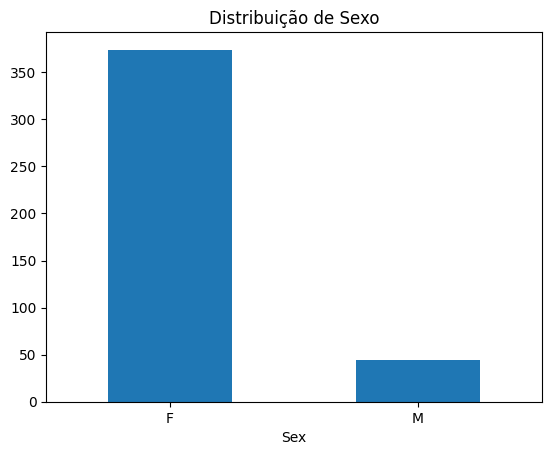

In [16]:
print(df['Sex'].value_counts())
print(df['Sex'].value_counts(normalize=True).round(3))
df['Sex'].value_counts().plot.bar(rot=0, title="Distribuição de Sexo")
plt.show()

## Variável-alvo (`Status`)
C = vivo ao fim do acompanhamento, CL = vivo por transplante de fígado, D = óbito.

Status
C     232
D     161
CL     25
Name: count, dtype: int64
Status
C     0.555
D     0.385
CL    0.060
Name: proportion, dtype: float64


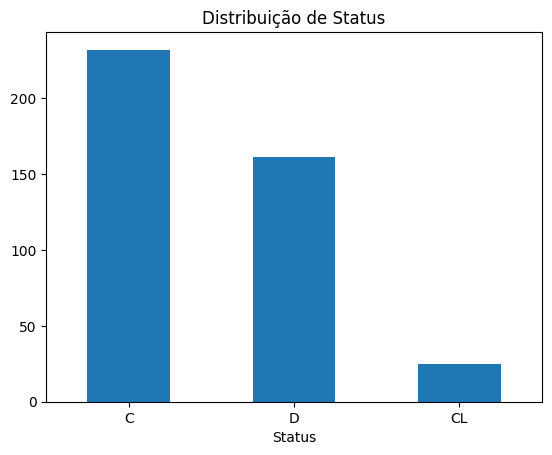

In [8]:
print(df["Status"].value_counts())
print(df["Status"].value_counts(normalize=True).round(3))
df["Status"].value_counts().plot.bar(rot=0, title="Distribuição de Status")
plt.show()

## Valores ausentes

In [9]:
ausentes = df.isna().sum()
ausentes[ausentes > 0].sort_values(ascending=False)

Tryglicerides    136
Cholesterol      134
Copper           108
Drug             106
Spiders          106
Hepatomegaly     106
Ascites          106
Alk_Phos         106
SGOT             106
Platelets         11
Stage              6
Prothrombin        2
dtype: int64

In [11]:
print("Pacientes sem 'Drug':", df["Drug"].isna().sum())
print("Linhas completas:", len(df.dropna()), "de", len(df))

Pacientes sem 'Drug': 106
Linhas completas: 276 de 418


## Atributos constantes e duplicados

In [12]:
print("Atributos constantes:", [c for c in df.columns if df[c].nunique() <= 1])
print("Linhas duplicadas:", df.drop(columns="ID").duplicated().sum())

Atributos constantes: []
Linhas duplicadas: 0


## Correlações

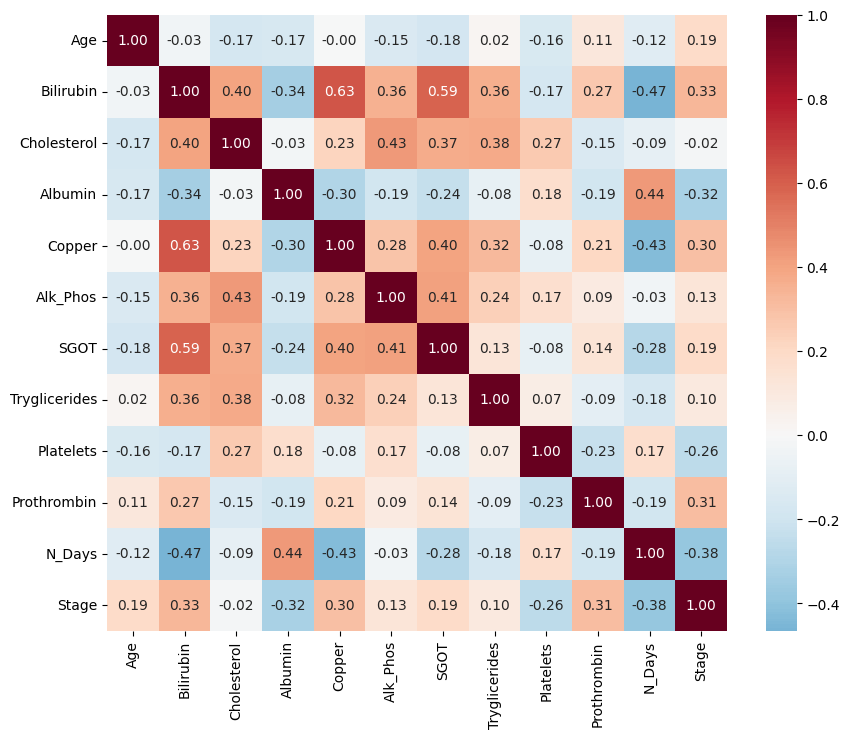

In [13]:
# spearman por que os dados não são normais e não são lineares
corr = df[numericas + ["N_Days", "Stage"]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.show()